# XPS Plotting – Publication Style

This notebook re-plots the CasaXPS export of this folder with the **publication
plot style** (fixed plot rectangle in cm, fonts declared in pt, `my_color_scale`)
that is also used in the other evaluation notebooks.

What it produces, per element:

| Figure | File |
|---|---|
| Waterfall of all samples (raw spectra only) | `<Element>_waterfall` |
| Waterfall of all samples **with fitted components filled** | `<Element>_waterfall_components` |
| Single spectrum with fitted components filled | `<Element>_<sample>_fit` |
| Stacked bar chart of the fitted component areas | `<Element>_component_areas` |
| Stacked bar chart of the component **fractions** | `<Element>_component_fractions` |

plus, over all elements: the raw area / At% tables and the corresponding bar and
line charts. If the samples are sputter steps of one sample (`DEPTH_PROFILE = True`),
the areas and At% are also plotted against the sputter time (section 9).

Every figure is written as `.svg` (vector, true cm size for Inkscape / LaTeX),
`.png` (scale 3) and `.html` (interactive) into `OUTPUT_DIR`. The spectra and all
calculated tables are saved as tab-separated `.txt` files into `saved_data/`.

### Exporting the data from CasaXPS

1. **Analyse the raw data** from the XPS in CasaXPS first: **energy calibration**
   and **curve fitting** are done in CasaXPS, this notebook only plots and
   integrates the result.
2. **Export all data** from CasaXPS into one file:
   select all data that should be exported on the right side of the CasaXPS
   window and press **"Overlay"** (shortcut `F2`) – all selected spectra now
   appear in the plot on the left.
3. Click on this plot once and press **"Save ASCII Data"** (the light blue disk
   icon at the top).
4. **Save the data** as a `.TXT` file in the "row of tables" format into
   `data/raw/`. Its name must contain the text in `FilterByNameList` (section 3).

## 1 – Packages

In [1]:
from pathlib import Path

##### Data Management
import pandas as pd
import numpy as np

##### Visualisieren
import plotly.express as px
import plotly.graph_objects as go
import plotly.colors as pcol

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.publication_plotly import add_reference_lines
from scientific_utils.publication_plotly import add_side_legend
from scientific_utils.publication_plotly import apply_style
from scientific_utils.xps.plotting import area_between
from scientific_utils.xps.plotting import clean_names
from scientific_utils.publication_plotly import cm
from scientific_utils.publication_plotly import color_series
from scientific_utils.publication_plotly import legend_size
from scientific_utils.xps.plotting import plot_spectrum_with_components
from scientific_utils.xps.plotting import plot_waterfall
from scientific_utils.publication_plotly import pt
from scientific_utils.xps.plotting import sample_of
from scientific_utils.publication_plotly import save_fig
from scientific_utils.xps.plotting import split_columns
from scientific_utils.publication_plotly import style_bars
from scientific_utils.xps.analysis import Extract_Sputter_Time_From_Name
from scientific_utils.xps.analysis import Extract_XPS_DetailSpectra_From_Multiple_Scans
from scientific_utils.xps.plotting import Matplotlib_SpiderWeb_Plot
from scientific_utils.xps.io import Read_CasaXPS_Spectra
# style constants (sizes in cm, fonts in pt) - defined once in publication_plotly.py
from scientific_utils.publication_plotly import ANNOT_FONT_PT, BAR_H_CM, BAR_MARGIN, BAR_W_CM, PLOT_H_CM, PLOT_W_CM, SPEC_H_CM

## 2 – Plot style

The whole style lives in `scientific_utils/publication_plotly.py` (sizes, fonts,
margins, `my_color_scale`). Change it there and every figure follows; the cell
above only imports the constants this notebook needs for its own bar and trend
charts.

**The idea:** SVG defines 1 inch = 96 CSS px. If every length is derived from
96, the exported SVG is *physically honest*: the black plot rectangle really is
4.0 cm wide in Inkscape and an 11 pt font really measures 11 pt. Because the
margins are fixed and `automargin=False`, the rectangle is identical in every
figure of the same class – figures can be placed side by side without rescaling.

**The side legend:** Plotly truncates its own legend as soon as it is taller than
the plot rectangle, and it silently shrinks the rectangle to make room for it —
both would break the fixed-size promise. The legend is therefore drawn by hand
from shapes and annotations in the right-hand margin: `legend_size()` returns the
extra room `apply_style()` needs, `add_side_legend()` draws it. Entry kinds:
`fill` (filled component), `box` (bar segment), `line`, `dash`, `marker`.

## 3 – Configuration of this experiment

Everything that is specific to *these* samples is collected here.

In [3]:
# ── Where the results go ──────────────────────────────────────────
OUTPUT_DIR = Path('./images_publication')
OUTPUT_DIR.mkdir(exist_ok=True)

data_outdir = Path('./saved_data')
data_outdir.mkdir(exist_ok=True)

# ── Reading the CasaXPS export ────────────────────────────────────
READ_ARGS = dict(
    path='./data/raw',                              # a
    FilterByNameList=['CAM'],              # b
    FileFormat='',                         # c
    StartString_of_the_wanted_Row='B.E.',  # d
    seperation_of_the_values='\t',         # e
    decimal_sign=',',                      # f
)

# ── Samples ───────────────────────────────────────────────────────
# The CasaXPS block name -> the label used in every figure. Reading the label
# from the column name (instead of zipping a list by position) keeps the
# assignment correct even when an element was not measured on every sample —
# F1s, for example, is missing for Rocksalt02.
SAMPLE_LABELS = {
    'Cathode_NCM_YS_pristine':  'pristine',
    'Cathode_NCM_Rocksalt01':   'washed01',
    'Cathode_NCM_Rocksalt02':   'washed02',
    'Cathode_NCM_Rocksalt03':   'washed03',
    'Cathode_NCM_Rocksalt04':   'washed04',
}
SAMPLE_ORDER  = list(SAMPLE_LABELS.values())
SAMPLE_COLORS = dict(zip(SAMPLE_ORDER, color_series(len(SAMPLE_ORDER))))

# ── Elements ──────────────────────────────────────────────────────
ELEMENTS = ['F1s', 'Li1s', 'C1s', 'O1s', 'Ni2p3', 'Mn2p3', 'Co2p3']  # detail spectra
SURVEY   = 'Su1s'                                                    # survey scan

# Vertical distance between two spectra in the waterfall plots. Each spectrum is
# scaled to 0...1 first, so 1.0 means "no gap", 1.3 means "30 % gap".
WATERFALL_OFFSET = {
    'F1s':   1.15,
    'Li1s':  1.15,
    'C1s':   1.30,
    'O1s':   1.30,
    'Ni2p3': 1.15,
    'Mn2p3': 1.15,
    'Co2p3': 1.15,
    'Su1s':  1.15,
}
DEFAULT_OFFSET = 1.15

# ── Reference lines (Binding Energy in eV) ────────────────────────
# Dashed lines with a label at known binding energies, drawn into the waterfall
# and single-spectrum plots. Elements that are not listed get no lines; lines
# outside the measured range are skipped.
REFERENCE_LINES = {
    'C1s': [(284.8, 'C-C'), (286.45, 'CH<sub>2</sub>'), (287.0, 'C-O'),
            (289.0, 'O-C=O'), (290.9, 'CF<sub>2</sub>')],
}

# ── Depth profile ─────────────────────────────────────────────────
# True when the samples are sputter steps of ONE sample. The sputter time is the
# first number in the sample label, so name the labels in SAMPLE_LABELS like
# '0 s', '600 s', ... Section 9 then plots area and At% against the sputter time.
DEPTH_PROFILE = False

# ── Integration limits (Binding Energy in eV) ─────────────────────
# Elements that are not listed are integrated over the full scan range.
integration_rois = {
    # 'Li1s': {'Li1s': [52.0, 58.0],
    #          'Ni3p': [63.9, 72.3]},
}

# ── RSF values (taken from CasaXPS) — needed for At% ──────────────
rsf_values = {
    'C1s': 0.314, 'O1s': 0.733, 'Bi4f7': 6.58735, 'Bi4f5': 5.25847,
    'Bi4f': 11.4696, 'Ba3d5': 8.43711, 'Na1s': 1.102, 'Na2s': 0.18,
    'Ti2p3': 1.524589, 'Ti2p1': 0.75969, 'Ti2p': 2.28678, 'Bi4d3': 2.21617,
    'Li1s': 0.028, 'F1s': 1.0, 'P2p': 0.604625, 'Ni2p3': 2.53066,
    'S2p': 0.668, 'N1s': 0.477, 'W4f': 3.52, 'Co3p': 0.447,
    'Ni3p': 0.598, 'Al2p': 0.193,
    # Mn2p3 and Co2p3 are NOT in this list. Add the CasaXPS values here if you
    # want them in the At% calculation — they are skipped (with a warning)
    # for as long as they are missing.
}

## 4 – Read the data

In [4]:
data = Read_CasaXPS_Spectra(*READ_ARGS.values())
print('Read %d file(s), first one has shape %s' % (len(data), data[0].shape))

-------------------
Following Files found in the chosen directory: %s ['CAM_Deg3_uncycled_cathodes', 'NCM831205_PC_as_recieved_CarbonSpectrum_SputterTime0000sec.TXT', 'NCM831205_PC_as_recieved_CarbonSpectrum_SputterTime0600sec.TXT', 'NCM831205_PC_as_recieved_CarbonSpectrum_SputterTime0900sec.TXT', 'NCM831205_PC_as_recieved_CarbonSpectrum_SputterTime1200sec.TXT']
-------------------
[]
Files found: ['CAM_Deg3_uncycled_cathodes']
-------------------
In total 1 files are selected. 
The name of the files are: 
['CAM_Deg3_uncycled_cathodes']
-------------------
------------------------------------------
reading files beginning at row 6
------------------------------------------
Read 1 file(s), first one has shape (2409, 261)


In [5]:
# Extract every detail spectrum once, keep it in memory and save it as .txt
# (all samples of one element side by side: B.E., raw data, components, background, envelope)
spectra = {}
for element in ELEMENTS + [SURVEY]:
    dfs = Extract_XPS_DetailSpectra_From_Multiple_Scans(data[0], element)
    labels = [sample_of(d, sample_labels=SAMPLE_LABELS) for d in dfs]
    spectra[element] = (dfs, labels)
    n_comp = len(split_columns(dfs[0])['comps']) if dfs else 0
    print(f'{element:>7}: {len(dfs)} spectra, {n_comp} fitted components  ->  {labels}')
    if dfs:
        pd.concat(dfs, axis=1).to_csv(data_outdir / f'{element}_spectra.txt', sep='\t', index=False)
print('Saved one <Element>_spectra.txt per element in', data_outdir)

    F1s: 5 spectra, 2 fitted components  ->  ['pristine', 'washed01', 'washed02', 'washed03', 'washed04']
   Li1s: 5 spectra, 2 fitted components  ->  ['pristine', 'washed01', 'washed02', 'washed03', 'washed04']
    C1s: 5 spectra, 5 fitted components  ->  ['pristine', 'washed01', 'washed02', 'washed03', 'washed04']
    O1s: 5 spectra, 5 fitted components  ->  ['pristine', 'washed01', 'washed02', 'washed03', 'washed04']
  Ni2p3: 5 spectra, 0 fitted components  ->  ['pristine', 'washed01', 'washed02', 'washed03', 'washed04']
  Mn2p3: 5 spectra, 0 fitted components  ->  ['pristine', 'washed01', 'washed02', 'washed03', 'washed04']
  Co2p3: 5 spectra, 0 fitted components  ->  ['pristine', 'washed01', 'washed02', 'washed03', 'washed04']
   Su1s: 5 spectra, 0 fitted components  ->  ['pristine', 'washed01', 'washed02', 'washed03', 'washed04']
Saved one <Element>_spectra.txt per element in saved_data


## 5 – Spectrum plots

`add_filled_component()` (in `publication_plotly.py`) is what keeps the fitted
peaks **filled down to the background**: for every component an invisible copy of
the background curve is added first, the component itself then uses
`fill='tonexty'`, so plotly closes the area between the two. The fill is the
component colour at 35 % opacity, the outline the full colour — overlapping peaks
stay readable.

`add_reference_lines()` draws the binding energies from `REFERENCE_LINES` as
dashed lines into the waterfall and single-spectrum plots.

### 5.1 – Waterfall, raw spectra only

In [6]:
for element in ELEMENTS:
    dfs, labels = spectra[element]
    if not dfs:
        continue
    fig = plot_waterfall(dfs, labels, with_components=False,
                         offset=WATERFALL_OFFSET.get(element, DEFAULT_OFFSET), sample_colors=SAMPLE_COLORS)
    add_reference_lines(fig, REFERENCE_LINES.get(element, []))
    save_fig(fig, f'{element}_waterfall', output_dir=OUTPUT_DIR)

Saved F1s_waterfall


Saved Li1s_waterfall


Saved C1s_waterfall


Saved O1s_waterfall


Saved Ni2p3_waterfall


Saved Mn2p3_waterfall


Saved Co2p3_waterfall


### 5.2 – Waterfall with the fitted components (filled)

Elements without a fit (Ni2p3, Mn2p3, Co2p3) simply come out as the raw curve
plus background.

In [7]:
for element in ELEMENTS:
    dfs, labels = spectra[element]
    if not dfs:
        continue
    fig = plot_waterfall(dfs, labels, with_components=True,
                         offset=WATERFALL_OFFSET.get(element, DEFAULT_OFFSET), sample_colors=SAMPLE_COLORS)
    add_reference_lines(fig, REFERENCE_LINES.get(element, []))
    save_fig(fig, f'{element}_waterfall_components', output_dir=OUTPUT_DIR)

Saved F1s_waterfall_components


Saved Li1s_waterfall_components


Saved C1s_waterfall_components


Saved O1s_waterfall_components


Saved Ni2p3_waterfall_components


Saved Mn2p3_waterfall_components


Saved Co2p3_waterfall_components


### 5.3 – Survey scan

In [8]:
dfs, labels = spectra[SURVEY]
if dfs:
    fig = plot_waterfall(dfs, labels, with_components=False,
                         offset=WATERFALL_OFFSET.get(SURVEY, DEFAULT_OFFSET),
                         annot_x=0.62,        # the survey is busy at high BE
                         plot_w_cm=8.0, plot_h_cm=SPEC_H_CM, sample_colors=SAMPLE_COLORS)
    save_fig(fig, f'{SURVEY}_survey_waterfall', output_dir=OUTPUT_DIR)

Saved Su1s_survey_waterfall


### 5.4 – Single spectra with their fit

One figure per sample and element. They are not shown inline (that would be
~35 figures) — look into `OUTPUT_DIR`.

In [9]:
for element in ELEMENTS:
    dfs, labels = spectra[element]
    for df, lab in zip(dfs, labels):
        fig = plot_spectrum_with_components(df, label=f'{element} – {lab}')
        add_reference_lines(fig, REFERENCE_LINES.get(element, []))
        save_fig(fig, f'{element}_{lab}_fit', show=False, output_dir=OUTPUT_DIR)

Saved F1s_pristine_fit
Saved F1s_washed01_fit
Saved F1s_washed02_fit
Saved F1s_washed03_fit
Saved F1s_washed04_fit
Saved Li1s_pristine_fit
Saved Li1s_washed01_fit
Saved Li1s_washed02_fit
Saved Li1s_washed03_fit
Saved Li1s_washed04_fit
Saved C1s_pristine_fit
Saved C1s_washed01_fit
Saved C1s_washed02_fit
Saved C1s_washed03_fit
Saved C1s_washed04_fit
Saved O1s_pristine_fit
Saved O1s_washed01_fit
Saved O1s_washed02_fit
Saved O1s_washed03_fit
Saved O1s_washed04_fit
Saved Ni2p3_pristine_fit
Saved Ni2p3_washed01_fit
Saved Ni2p3_washed02_fit
Saved Ni2p3_washed03_fit
Saved Ni2p3_washed04_fit
Saved Mn2p3_pristine_fit
Saved Mn2p3_washed01_fit
Saved Mn2p3_washed02_fit
Saved Mn2p3_washed03_fit
Saved Mn2p3_washed04_fit
Saved Co2p3_pristine_fit
Saved Co2p3_washed01_fit
Saved Co2p3_washed02_fit
Saved Co2p3_washed03_fit
Saved Co2p3_washed04_fit


In [10]:
# A single one shown inline as a check of the style
df, lab = spectra['C1s'][0][0], spectra['C1s'][1][0]
fig = plot_spectrum_with_components(df, label=f'C1s – {lab}')
add_reference_lines(fig, REFERENCE_LINES.get('C1s', []))
fig.show()

## 6 – Peak areas

`area_between()` (in `publication_plotly.py`) integrates (data − background) with
the trapezoidal rule, optionally between the limits in `integration_rois`. It is
the same calculation as `Determine_Area_XPS()` from `scientific_utils.xps.analysis`.

The results go into one long table (`All_Elements_Results_LongFormat.txt`) and,
split by element, into one `<Element>_Results_LongFormat.txt` each.

In [11]:
rows = []
for element in ELEMENTS:
    dfs, labels = spectra[element]
    regions = integration_rois.get(element, {element: [None, None]})

    for region_name, (lower, upper) in regions.items():
        for df, lab in zip(dfs, labels):
            c = split_columns(df)
            names = clean_names(c['comps'])
            rows.append(dict(Sample=lab, Element=element, Region=region_name,
                             Component='Total Region',
                             Area=area_between(df, c['x'], c['raw'], c['bg'], lower, upper),
                             Lower_Lim=lower, Upper_Lim=upper))
            for k, col in enumerate(c['comps']):
                rows.append(dict(Sample=lab, Element=element, Region=region_name,
                                 Component=names[k],
                                 Area=area_between(df, c['x'], col, c['bg'], lower, upper),
                                 Lower_Lim=lower, Upper_Lim=upper))

master_df_long = pd.DataFrame(rows)
master_df_long.to_csv(data_outdir / 'All_Elements_Results_LongFormat.txt',
                      sep='\t', index=False)
print('Saved', data_outdir / 'All_Elements_Results_LongFormat.txt')

for element, sub in master_df_long.groupby('Element', sort=False):
    sub.to_csv(data_outdir / f'{element}_Results_LongFormat.txt', sep='\t', index=False)
print('Saved one <Element>_Results_LongFormat.txt per element')
master_df_long.head(12)

Saved saved_data\All_Elements_Results_LongFormat.txt
Saved one <Element>_Results_LongFormat.txt per element


,Sample,Element,Region,Component,Area,Lower_Lim,Upper_Lim
0,pristine,F1s,F1s,Total Region,42476.619298,None,None
1,pristine,F1s,F1s,C-F (PVdF),38807.591895,None,None
2,pristine,F1s,F1s,LiF,3239.819336,None,None
3,washed01,F1s,F1s,Total Region,49090.953642,None,None
4,washed01,F1s,F1s,C-F (PVdF),43427.247684,None,None
5,washed01,F1s,F1s,LiF,5129.605469,None,None
6,washed02,F1s,F1s,Total Region,49188.429809,None,None
7,washed02,F1s,F1s,C-F (PVdF),44531.187082,None,None
8,washed02,F1s,F1s,LiF,4065.519992,None,None
9,washed03,F1s,F1s,Total Region,47917.163308,None,None


## 7 – Atomic percentages

Only the `Total Region` rows enter the At% calculation, and only the regions for
which an RSF value is defined.

In [12]:
df_at = master_df_long[master_df_long['Component'] == 'Total Region'].copy()
df_at['RSF'] = df_at['Region'].map(rsf_values)

missing = sorted(df_at.loc[df_at['RSF'].isnull(), 'Region'].unique())
if missing:
    print('No RSF value for: %s  ->  excluded from the At%% calculation.' % missing)
    print('Add the CasaXPS values to `rsf_values` to include them.')
    df_at = df_at[df_at['RSF'].notnull()].copy()

df_at['Normalized_Area'] = df_at['Area'] / df_at['RSF']
df_at['At%'] = 100 * df_at['Normalized_Area'] / df_at.groupby('Sample')['Normalized_Area'].transform('sum')

results_table = df_at[['Sample', 'Region', 'Area', 'RSF', 'At%']].copy()
results_table.to_csv(data_outdir / 'Atomic_Percentages_Results.txt', sep='\t', index=False)
print('Saved', data_outdir / 'Atomic_Percentages_Results.txt')

df_pivot = results_table.pivot(index='Sample', columns='Region', values='At%')
df_pivot = df_pivot.reindex([s for s in SAMPLE_ORDER if s in df_pivot.index])
df_pivot

No RSF value for: ['Co2p3', 'Mn2p3']  ->  excluded from the At% calculation.
Add the CasaXPS values to `rsf_values` to include them.
Saved saved_data\Atomic_Percentages_Results.txt


Region,C1s,F1s,Li1s,Ni2p3,O1s
Sample,,,,,
pristine,51.631172,12.076332,8.436800,5.279046,22.576651
washed01,50.963022,14.764419,6.670679,7.579454,20.022427
washed02,51.768176,14.913820,5.251497,8.055951,20.010555
washed03,51.425862,15.119115,5.000439,8.497858,19.956726
washed04,53.415203,14.746478,4.612500,8.009096,19.216723


## 8 – Bar charts

Bar charts need two departures from the default style, both of them because the
x axis carries categories rather than numbers:

* the category axis gets **no ticks, no minor ticks and no SI tick format** —
  none of them mean anything between two samples;
* the rectangle is **6.0 × 3.3 cm** instead of 4.0 × 3.3 cm and the bottom
  margin is deeper, so five rotated sample names fit underneath.

Everything else — line widths, fonts, the box, the colour scale — is unchanged,
and all bar charts again share one identical rectangle.

### 8.1 – Fitted component areas per element

In [13]:
for element in ELEMENTS:
    sub = master_df_long[(master_df_long['Element'] == element) &
                         (master_df_long['Component'] != 'Total Region')]
    if sub.empty:
        continue
    comps = list(dict.fromkeys(sub['Component']))
    colors = color_series(len(comps))

    fig = px.bar(sub, x='Sample', y='Area', color='Component',
                 color_discrete_sequence=colors,
                 category_orders={'Component': comps, 'Sample': SAMPLE_ORDER})
    style_bars(fig, '', '<i>Area</i> / CPS eV',
               entries=[(n, colors[k], 'box') for k, n in enumerate(comps)], sample_order=SAMPLE_ORDER)
    save_fig(fig, f'{element}_component_areas', output_dir=OUTPUT_DIR)

Saved F1s_component_areas


Saved Li1s_component_areas


Saved C1s_component_areas


Saved O1s_component_areas


### 8.2 – Component fractions (each sample normalised to 100 %)

Easier to read than the absolute areas when the total intensity differs between
samples.

In [14]:
for element in ELEMENTS:
    sub = master_df_long[(master_df_long['Element'] == element) &
                         (master_df_long['Component'] != 'Total Region')].copy()
    if sub.empty:
        continue
    sub['Fraction'] = 100 * sub['Area'] / sub.groupby('Sample')['Area'].transform('sum')
    comps = list(dict.fromkeys(sub['Component']))
    colors = color_series(len(comps))

    fig = px.bar(sub, x='Sample', y='Fraction', color='Component',
                 color_discrete_sequence=colors,
                 category_orders={'Component': comps, 'Sample': SAMPLE_ORDER})
    style_bars(fig, '', '<i>Fraction</i> / %',
               entries=[(n, colors[k], 'box') for k, n in enumerate(comps)],
               y_tickformat=None, y_range=[0, 105], sample_order=SAMPLE_ORDER)
    save_fig(fig, f'{element}_component_fractions', output_dir=OUTPUT_DIR)

Saved F1s_component_fractions


Saved Li1s_component_fractions


Saved C1s_component_fractions


Saved O1s_component_fractions


### 8.3 – Atomic percentage per sample

In [15]:
regions = list(df_pivot.columns)
colors = color_series(len(regions))

fig = px.bar(results_table, x='Sample', y='At%', color='Region',
             color_discrete_sequence=colors,
             category_orders={'Region': regions, 'Sample': SAMPLE_ORDER})
style_bars(fig, '', '<i>Atomic Conc.</i> / At%',
           entries=[(r, colors[k], 'box') for k, r in enumerate(regions)],
           barmode='group', y_tickformat=None, sample_order=SAMPLE_ORDER)
save_fig(fig, 'AtomPercent_grouped', output_dir=OUTPUT_DIR)

Saved AtomPercent_grouped


In [16]:
fig = px.bar(results_table, x='Sample', y='At%', color='Region',
             color_discrete_sequence=colors,
             category_orders={'Region': regions, 'Sample': SAMPLE_ORDER})
style_bars(fig, '', '<i>Atomic Conc.</i> / At%',
           entries=[(r, colors[k], 'box') for k, r in enumerate(regions)],
           barmode='stack', y_tickformat=None, y_range=[0, 105], sample_order=SAMPLE_ORDER)
save_fig(fig, 'AtomPercent_stacked', output_dir=OUTPUT_DIR)

Saved AtomPercent_stacked


### 8.4 – Atomic percentage as a trend over the samples

In [17]:
fig = go.Figure()
for k, region in enumerate(regions):
    fig.add_scatter(x=df_pivot.index, y=df_pivot[region], mode='lines+markers',
                    name=region, showlegend=False,
                    line=dict(color=colors[k], width=1.5),
                    marker=dict(color=colors[k], size=5,
                                line=dict(color='black', width=0.6)))

entries = [(r, colors[k], 'line') for k, r in enumerate(regions)]
right, bottom = legend_size(entries, BAR_H_CM)
apply_style(fig, '', '<i>Atomic Conc.</i> / At%',
            plot_w_cm=BAR_W_CM, plot_h_cm=BAR_H_CM, margin=BAR_MARGIN,
            x_ticks='', x_minor=False, x_tickformat=None,
            y_tickformat=None,
            extra_right_px=right, extra_bottom_px=bottom)
add_side_legend(fig, entries, BAR_W_CM, BAR_H_CM)
fig.update_xaxes(tickangle=-45, categoryorder='array', categoryarray=SAMPLE_ORDER)
save_fig(fig, 'AtomPercent_trend', output_dir=OUTPUT_DIR)

Saved AtomPercent_trend


In [18]:
# Same trend, zoomed onto the minor components
fig = go.Figure()
for k, region in enumerate(regions):
    fig.add_scatter(x=df_pivot.index, y=df_pivot[region], mode='lines+markers',
                    name=region, showlegend=False,
                    line=dict(color=colors[k], width=1.5),
                    marker=dict(color=colors[k], size=5,
                                line=dict(color='black', width=0.6)))

right, bottom = legend_size(entries, BAR_H_CM)
apply_style(fig, '', '<i>Atomic Conc.</i> / At%',
            plot_w_cm=BAR_W_CM, plot_h_cm=BAR_H_CM, margin=BAR_MARGIN,
            x_ticks='', x_minor=False, x_tickformat=None,
            y_tickformat=None,
            extra_right_px=right, extra_bottom_px=bottom)
add_side_legend(fig, entries, BAR_W_CM, BAR_H_CM)
fig.update_xaxes(tickangle=-45, categoryorder='array', categoryarray=SAMPLE_ORDER)
fig.update_yaxes(range=[-0.05, 5.5])
save_fig(fig, 'AtomPercent_trend_zoom', output_dir=OUTPUT_DIR)

Saved AtomPercent_trend_zoom


### 8.4b – Atomic percentage as spider web plot

The same At% values as a radar chart (Matplotlib): every sample is one polygon, every element one axis.

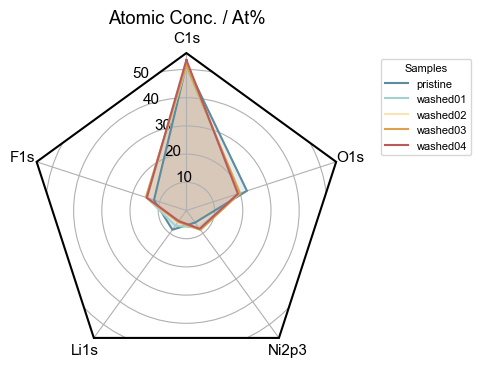

In [19]:
# the Plotly colours (rgb strings) are converted to Matplotlib colours (tuples from 0 to 1)
spider_colors = pcol.convert_colors_to_same_type(color_series(len(df_pivot)), colortype='tuple')[0]

SpiderWebParameters = {'list_of_column_names' : regions,
                       'list_of_labels' : regions,
                       'list_of_list_of_Curve_style_options' : [[color, 0.15, sample] for color, sample in zip(spider_colors, df_pivot.index)],
                       'list_of_axis_style_options' : ['Yes', (10, 20, 30, 40, 50)],
                       'list_for_saving_options' : [True, 'AtomPercent_spider_web'],
                       'list_for_title_legend_options' : ['Atomic Conc. / At%', 'Samples']
                       }

Matplotlib_SpiderWeb_Plot(df_pivot, SpiderWebParameters)

### 8.5 – The signals of interest

The four signals that carry the degradation information:

| Signal | taken from |
|---|---|
| Ni 2p3 | the whole `Ni2p3` region (there is no fit for it) |
| Li-NCM | the `Li-NCM` component of `Li1s` |
| RSL-O  | the `RSL-O` component of `O1s` (rocksalt) |
| NCM-O  | the `NCM-O` component of `O1s` (layered oxide lattice) |

Their raw counts span two orders of magnitude (Li-NCM ≈ 400, Ni 2p3 ≈ 60 000),
so they get **one panel each with its own y axis** — on a shared linear axis
Li-NCM would collapse into an invisible line. The two charts that *do* put all
four on one axis use quantities that are comparable by construction: the counts
relative to the pristine sample, and the RSF-corrected atomic percentage.

In [20]:
# (Element, component name in master_df_long, label used in the figures)
# 'Total Region' = the whole region, i.e. the raw peak area without a fit.
SIGNALS_OF_INTEREST = [
    ('Ni2p3', 'Total Region', 'Ni 2p3'),
    ('Li1s',  'Li-NCM',       'Li-NCM'),
    ('O1s',   'RSL-O',        'RSL-O'),
    ('O1s',   'NCM-O',        'NCM-O'),
]
REFERENCE_SAMPLE = 'pristine'      # the 100 % level in the relative chart

SIGNAL_ORDER  = [lab for _, _, lab in SIGNALS_OF_INTEREST]
SIGNAL_COLORS = dict(zip(SIGNAL_ORDER, color_series(len(SIGNAL_ORDER))))

In [21]:
# The At% denominator is the one section 7 already uses, so the numbers here and
# in the AtomPercent figures rest on the same basis.
sample_totals = df_at.groupby('Sample')['Normalized_Area'].sum()

rows = []
for element, component, label in SIGNALS_OF_INTEREST:
    sub = master_df_long[(master_df_long['Element'] == element) &
                         (master_df_long['Component'] == component)]
    if sub.empty:
        print(f'!! {element} / {component} not found - check the name against '
              f'master_df_long["Component"].unique().')
        continue
    rsf = rsf_values.get(element)
    if rsf is None:
        print(f'!! no RSF for {element} - At% stays empty for {label}.')
    for r in sub.itertuples():
        norm = r.Area / rsf if rsf else np.nan
        rows.append({'Sample': r.Sample, 'Signal': label, 'Element': element,
                     'Component': component, 'Area': r.Area, 'RSF': rsf,
                     'Normalized_Area': norm,
                     'At%': 100 * norm / sample_totals.get(r.Sample, np.nan)})

df_signals = pd.DataFrame(rows)

# counts relative to the reference sample
base = df_signals[df_signals['Sample'] == REFERENCE_SAMPLE].set_index('Signal')['Area']
df_signals['Rel_Area'] = 100 * df_signals['Area'] / df_signals['Signal'].map(base)

df_signals.to_csv(data_outdir / 'SignalsOfInterest.txt', sep='\t', index=False)
print('Saved', data_outdir / 'SignalsOfInterest.txt')

df_signals.pivot(index='Sample', columns='Signal', values='Area') \
          .reindex([s for s in SAMPLE_ORDER if s in set(df_signals['Sample'])])

Saved saved_data\SignalsOfInterest.txt


Signal,Li-NCM,NCM-O,Ni 2p3,RSL-O
Sample,,,,
pristine,519.198425,18022.384766,46989.857473,4496.680176
washed01,522.707458,21377.335837,63775.935606,4394.998047
washed02,436.389526,20340.240069,67239.533510,5386.286133
washed03,406.599121,19700.483510,68156.612354,5117.745605
washed04,328.349243,16790.414054,60866.913584,5874.604492


#### Raw counts, one panel per signal

The bars are coloured by sample (the same colours as in the waterfall plots) and
the signal is named above the box, so these panels need no legend.

In [22]:
for label in SIGNAL_ORDER:
    sub = df_signals[df_signals['Signal'] == label]
    if sub.empty:
        continue
    fig = px.bar(sub, x='Sample', y='Area', color='Sample',
                 color_discrete_map=SAMPLE_COLORS,
                 category_orders={'Sample': SAMPLE_ORDER})
    style_bars(fig, '', '<i>Area</i> / CPS eV', entries=(), sample_order=SAMPLE_ORDER)
    fig.add_annotation(xref='paper', x=0.0, yref='paper', y=1.02, text=label,
                       xanchor='left', yanchor='bottom', showarrow=False,
                       font=dict(size=pt(ANNOT_FONT_PT), color='black'))
    save_fig(fig, f"Signal_{label.replace(' ', '')}_counts", output_dir=OUTPUT_DIR)

Saved Signal_Ni2p3_counts


Saved Signal_Li-NCM_counts


Saved Signal_RSL-O_counts


Saved Signal_NCM-O_counts


#### All four signals relative to the pristine sample

Every signal is scaled to its own pristine value = 100 %. That is what makes the
*change* in counts comparable between signals of very different size. The dashed
line marks the pristine level.

In [23]:
fig = px.bar(df_signals, x='Sample', y='Rel_Area', color='Signal',
             color_discrete_sequence=[SIGNAL_COLORS[s] for s in SIGNAL_ORDER],
             category_orders={'Signal': SIGNAL_ORDER, 'Sample': SAMPLE_ORDER})
style_bars(fig, '', f'<i>Area</i> / % of {REFERENCE_SAMPLE}',
           entries=[(s, SIGNAL_COLORS[s], 'box') for s in SIGNAL_ORDER],
           barmode='group', y_tickformat=None, sample_order=SAMPLE_ORDER)
fig.add_hline(y=100, line=dict(color='black', width=1, dash='dash'))
save_fig(fig, 'SignalsOfInterest_counts_relative', output_dir=OUTPUT_DIR)

Saved SignalsOfInterest_counts_relative


#### Atomic percentage of the four signals

RSF-corrected and referred to the same total as section 7 — these are atomic
percentages of the whole detected composition, not fractions within their own
element.

In [24]:
fig = px.bar(df_signals, x='Sample', y='At%', color='Signal',
             color_discrete_sequence=[SIGNAL_COLORS[s] for s in SIGNAL_ORDER],
             category_orders={'Signal': SIGNAL_ORDER, 'Sample': SAMPLE_ORDER})
style_bars(fig, '', '<i>Atomic Conc.</i> / At%',
           entries=[(s, SIGNAL_COLORS[s], 'box') for s in SIGNAL_ORDER],
           barmode='group', y_tickformat=None, sample_order=SAMPLE_ORDER)
save_fig(fig, 'SignalsOfInterest_atompercent', output_dir=OUTPUT_DIR)

Saved SignalsOfInterest_atompercent


In [25]:
# The same At% data as a trend - the direction of the change at a glance
fig = go.Figure()
for label in SIGNAL_ORDER:
    sub = df_signals[df_signals['Signal'] == label].set_index('Sample')
    sub = sub.reindex([s for s in SAMPLE_ORDER if s in sub.index])
    fig.add_scatter(x=sub.index, y=sub['At%'], mode='lines+markers', name=label,
                    showlegend=False,
                    line=dict(color=SIGNAL_COLORS[label], width=1.5),
                    marker=dict(color=SIGNAL_COLORS[label], size=5,
                                line=dict(color='black', width=0.6)))

entries = [(s, SIGNAL_COLORS[s], 'line') for s in SIGNAL_ORDER]
right, bottom = legend_size(entries, BAR_H_CM)
apply_style(fig, '', '<i>Atomic Conc.</i> / At%',
            plot_w_cm=BAR_W_CM, plot_h_cm=BAR_H_CM, margin=BAR_MARGIN,
            x_ticks='', x_minor=False, x_tickformat=None, y_tickformat=None,
            extra_right_px=right, extra_bottom_px=bottom)
add_side_legend(fig, entries, BAR_W_CM, BAR_H_CM)
fig.update_xaxes(tickangle=-45, categoryorder='array', categoryarray=SAMPLE_ORDER)
save_fig(fig, 'SignalsOfInterest_atompercent_trend', output_dir=OUTPUT_DIR)

Saved SignalsOfInterest_atompercent_trend


### 8.6 – RSL-O and NCM-O summed

Both components sit on the same O1s region, so their areas may simply be added:
the sum is the total lattice-oxygen signal, rocksalt plus layered oxide.

Two views of the same number — the **stacked** chart, where the height of the
whole bar *is* the sum and the split between the two contributions stays
visible, and the **plain total**, which is the sum on its own.

In [26]:
SUM_SIGNALS = ['RSL-O', 'NCM-O']
SUM_LABEL   = ' + '.join(SUM_SIGNALS)
SUM_STEM    = 'Sum_' + '_'.join(s.replace('-', '') for s in SUM_SIGNALS)

df_sum_parts = df_signals[df_signals['Signal'].isin(SUM_SIGNALS)].copy()

df_sum = (df_sum_parts.groupby('Sample', as_index=False)[['Area', 'Normalized_Area']]
                      .sum())
df_sum['At%'] = 100 * df_sum['Normalized_Area'] / df_sum['Sample'].map(sample_totals)
df_sum['Signal'] = SUM_LABEL
df_sum = (df_sum.set_index('Sample')
                .reindex([s for s in SAMPLE_ORDER if s in set(df_sum['Sample'])])
                .reset_index())

df_sum.to_csv(data_outdir / f'{SUM_STEM}.txt', sep='\t', index=False)
print('Saved', data_outdir / f'{SUM_STEM}.txt')
df_sum[['Sample', 'Area', 'At%']]

Saved saved_data\Sum_RSLO_NCMO.txt


,Sample,Area,At%
0,pristine,22519.064941,8.734368
1,washed01,25772.333884,10.574617
2,washed02,25726.526202,10.641506
3,washed03,24818.229115,10.683218
4,washed04,22665.018546,10.296465


In [27]:
# Stacked: the total bar height is the sum, the split stays readable
fig = px.bar(df_sum_parts, x='Sample', y='Area', color='Signal',
             color_discrete_sequence=[SIGNAL_COLORS[s] for s in SUM_SIGNALS],
             category_orders={'Signal': SUM_SIGNALS, 'Sample': SAMPLE_ORDER})
style_bars(fig, '', '<i>Area</i> / CPS eV',
           entries=[(s, SIGNAL_COLORS[s], 'box') for s in SUM_SIGNALS],
           barmode='stack', sample_order=SAMPLE_ORDER)
save_fig(fig, f'{SUM_STEM}_stacked', output_dir=OUTPUT_DIR)

Saved Sum_RSLO_NCMO_stacked


In [28]:
# The plain sum, one bar per sample
fig = px.bar(df_sum, x='Sample', y='Area', color='Sample',
             color_discrete_map=SAMPLE_COLORS,
             category_orders={'Sample': SAMPLE_ORDER})
style_bars(fig, '', '<i>Area</i> / CPS eV', entries=(), sample_order=SAMPLE_ORDER)
fig.add_annotation(xref='paper', x=0.0, yref='paper', y=1.02, text=SUM_LABEL,
                   xanchor='left', yanchor='bottom', showarrow=False,
                   font=dict(size=pt(ANNOT_FONT_PT), color='black'))
save_fig(fig, SUM_STEM, output_dir=OUTPUT_DIR)

Saved Sum_RSLO_NCMO


### 8.7 – Li-NCM, Ni and the summed lattice oxygen

The three signals that describe the NCM lattice itself: lattice lithium
(`Li-NCM`), nickel (`Ni2p3`) and the summed lattice oxygen (`RSL-O + NCM-O`).

Two readings of "atomic fraction", both plotted because they answer different
questions:

* **At% of the whole composition** (grouped bars) — how much of *everything*
  detected is lattice Li / Ni / O. This is the same scale as sections 7 and 8.5,
  so the bars can be compared with the other At% figures.
* **Fraction among these three** (stacked to 100 %) — the Li : Ni : O ratio of
  the lattice, with surface species, carbon and fluorine divided out. This is
  the one that shows a change in stoichiometry rather than a change in how much
  surface layer sits on top.

In [29]:
LATTICE_SIGNALS = ['Li-NCM', 'Ni 2p3', SUM_LABEL]     # Li : Ni : O order
# blue / orange / red - skipping the pale middle of the scale, which is too
# light to read as a bar fill
LATTICE_COLORS  = dict(zip(LATTICE_SIGNALS,
                           color_series(3, positions=[1.0, 0.25, 0.0])))

cols = ['Sample', 'Signal', 'Area', 'Normalized_Area', 'At%']
df_lattice = pd.concat([
    df_signals.loc[df_signals['Signal'].isin(LATTICE_SIGNALS), cols],
    df_sum[cols],
], ignore_index=True)

# Fraction among these three only -> the lattice stoichiometry.
# RSF-corrected areas are what may be compared between elements, so the
# fraction is built from Normalized_Area, not from the raw counts.
df_lattice['Fraction'] = 100 * df_lattice['Normalized_Area'] / \
    df_lattice.groupby('Sample')['Normalized_Area'].transform('sum')

df_lattice.to_csv(data_outdir / 'LatticeSignals.txt', sep='\t', index=False)
print('Saved', data_outdir / 'LatticeSignals.txt')

df_lattice.pivot(index='Sample', columns='Signal', values='Fraction') \
          .reindex([s for s in SAMPLE_ORDER if s in set(df_lattice['Sample'])])[
              LATTICE_SIGNALS].round(2)

Saved saved_data\LatticeSignals.txt


Signal,Li-NCM,Ni 2p3,RSL-O + NCM-O
Sample,,,
pristine,27.34,27.37,45.29
washed01,23.62,31.89,44.49
washed02,20.17,34.39,45.43
washed03,19.28,35.76,44.96
washed04,17.58,36.06,46.36


In [30]:
# At% of the whole detected composition
fig = px.bar(df_lattice, x='Sample', y='At%', color='Signal',
             color_discrete_sequence=[LATTICE_COLORS[s] for s in LATTICE_SIGNALS],
             category_orders={'Signal': LATTICE_SIGNALS, 'Sample': SAMPLE_ORDER})
style_bars(fig, '', '<i>Atomic Conc.</i> / At%',
           entries=[(s, LATTICE_COLORS[s], 'box') for s in LATTICE_SIGNALS],
           barmode='group', y_tickformat=None, sample_order=SAMPLE_ORDER)
save_fig(fig, 'LatticeSignals_atompercent', output_dir=OUTPUT_DIR)

Saved LatticeSignals_atompercent


In [31]:
# Fraction among the three -> Li : Ni : O ratio of the lattice
fig = px.bar(df_lattice, x='Sample', y='Fraction', color='Signal',
             color_discrete_sequence=[LATTICE_COLORS[s] for s in LATTICE_SIGNALS],
             category_orders={'Signal': LATTICE_SIGNALS, 'Sample': SAMPLE_ORDER})
style_bars(fig, '', '<i>Fraction</i> / %',
           entries=[(s, LATTICE_COLORS[s], 'box') for s in LATTICE_SIGNALS],
           barmode='stack', y_tickformat=None, y_range=[0, 105], sample_order=SAMPLE_ORDER)
save_fig(fig, 'LatticeSignals_fraction', output_dir=OUTPUT_DIR)

Saved LatticeSignals_fraction


## 9 – Depth profile (only with `DEPTH_PROFILE = True`)

When the samples are sputter steps of one sample, the sputter time is read from
the sample label (the first number in it, `Extract_Sputter_Time_From_Name()`, e.g.
`'600 s'` → 600) and the area of every region (`Total Region`) and its At% are
plotted against it on a numeric x axis. For the washing series of this folder
`DEPTH_PROFILE = False` and the section is skipped.

In [32]:
if DEPTH_PROFILE:
    df_depth = master_df_long.loc[master_df_long['Component'] == 'Total Region', ['Sample', 'Region', 'Area']]
    df_depth = df_depth.merge(df_at[['Sample', 'Region', 'At%']], on=['Sample', 'Region'], how='left')
    df_depth['Sputter Time'] = df_depth['Sample'].apply(Extract_Sputter_Time_From_Name)
    df_depth = df_depth.sort_values(['Region', 'Sputter Time'])

    df_depth.to_csv(data_outdir / 'DepthProfile.txt', sep='\t', index=False)
    print('Saved', data_outdir / 'DepthProfile.txt')
    print(df_depth.pivot(index='Sputter Time', columns='Region', values='Area'))
else:
    print('DEPTH_PROFILE = False -> no depth profile.')

DEPTH_PROFILE = False -> no depth profile.


In [33]:
if DEPTH_PROFILE:
    depth_regions = list(dict.fromkeys(df_depth['Region']))
    depth_colors = dict(zip(depth_regions, color_series(len(depth_regions))))

    # At% is empty for the regions without an RSF value -> they only appear in the area plot
    for y_col, y_label, y_format, stem in [('Area', '<i>Area</i> / CPS eV', '~s', 'DepthProfile_area'),
                                           ('At%', '<i>Atomic Conc.</i> / At%', None, 'DepthProfile_atompercent')]:
        fig = go.Figure()
        entries = []
        for region in depth_regions:
            sub = df_depth[df_depth['Region'] == region].dropna(subset=[y_col])
            if sub.empty:
                continue
            fig.add_scatter(x=sub['Sputter Time'], y=sub[y_col], mode='lines+markers',
                            name=region, showlegend=False,
                            line=dict(color=depth_colors[region], width=1.5),
                            marker=dict(color=depth_colors[region], size=5,
                                        line=dict(color='black', width=0.6)))
            entries.append((region, depth_colors[region], 'line'))

        right, bottom = legend_size(entries, PLOT_H_CM)
        apply_style(fig, '<i>Sputter Time</i> / s', y_label,
                    x_tickformat=None, y_tickformat=y_format,
                    extra_right_px=right, extra_bottom_px=bottom)
        add_side_legend(fig, entries, PLOT_W_CM, PLOT_H_CM)
        save_fig(fig, stem, output_dir=OUTPUT_DIR)